In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf

tickers = ["KO", "PEP"]
print(f"Téléchargement des données historiques pour : {tickers}...")
data = yf.download(tickers, start="2023-01-01", end="2026-01-01")['Close']
data = data.dropna()

print("Aperçu des premières lignes de données :")
print(data.head())

Téléchargement des données historiques pour : ['KO', 'PEP']...


Cookie fetch from fc.yahoo.com failed (CertificateVerifyError), continuing without it
Cookie/crumb fetch failed (CertificateVerifyError), continuing without crumb
Cookie/crumb fetch failed (CertificateVerifyError), continuing without crumb
[*********************100%***********************]  2 of 2 completed

Aperçu des premières lignes de données :
Ticker             KO         PEP
Date                             
2023-01-03  56.423210  157.697601
2023-01-04  56.396324  157.310883
2023-01-05  55.750973  155.667160
2023-01-06  56.826561  159.183136
2023-01-09  56.118454  157.627304


In [2]:
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
from statsmodels.tsa.stattools import adfuller

# Définition des variables pour la régression OLS : Y = KO, X = PEP
Y = data['KO']
X = sm.add_constant(data['PEP'])

# Ajustement du modèle OLS
ols_model = OLS(Y, X).fit()
alpha = ols_model.params['const']
beta = ols_model.params['PEP']

print(f"Paramètres estimés : Alpha = {alpha:.4f}, Beta = {beta:.4f}")

# Calcul du spread de prix
spread = data['KO'] - (beta * data['PEP'] + alpha)

# Test de Dickey-Fuller Augmenté (ADF) pour valider la stationnarité du spread
adf_test = adfuller(spread.dropna())
print(f"\n--- Résultat du test ADF sur le Spread ---")
print(f"Statistique ADF : {adf_test[0]:.4f}")
print(f"p-value : {adf_test[1]:.4f}")

Paramètres estimés : Alpha = 102.2401, Beta = -0.2798

--- Résultat du test ADF sur le Spread ---
Statistique ADF : -2.3220
p-value : 0.1650


/tmp/ipykernel_427822/104446736.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_test = adfuller(spread.dropna())


In [3]:
# Définition de la fenêtre glissante (ex: 20 jours)
window = 20

# Calcul de la moyenne et de l'écart-type mobiles du spread
rolling_mean = spread.rolling(window=window).mean()
rolling_std = spread.rolling(window=window).std()

# Calcul du Z-Score
z_score = (spread - rolling_mean) / rolling_std

# Création d'un DataFrame de travail pour stocker les résultats de la stratégie
df_strategy = pd.DataFrame(index=data.index)
df_strategy['KO'] = data['KO']
df_strategy['PEP'] = data['PEP']
df_strategy['Spread'] = spread
df_strategy['Z_Score'] = z_score

print("Aperçu des derniers Z-Scores calculés :")
print(df_strategy[['Spread', 'Z_Score']].tail())

Aperçu des derniers Z-Scores calculés :
              Spread   Z_Score
Date                          
2025-12-24  5.566866 -1.350969
2025-12-26  5.342304 -1.405625
2025-12-29  5.751687 -0.965708
2025-12-30  5.641688 -0.999852
2025-12-31  5.310943 -1.215909


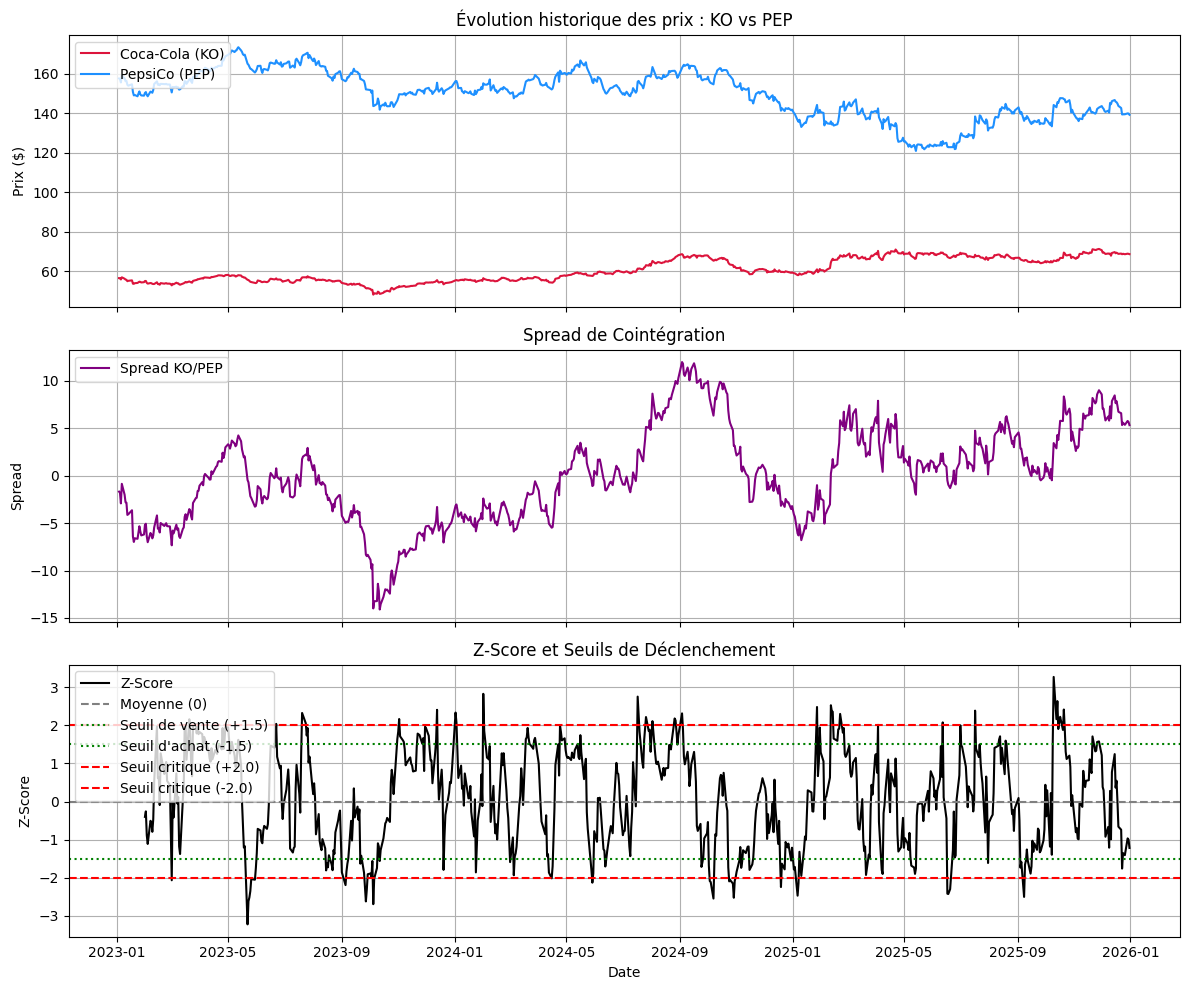

In [4]:
import matplotlib.pyplot as plt

# Création d'une figure avec trois sous-graphiques partagant l'axe temporel
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# 1. Évolution historique des prix des deux actifs
axes[0].plot(data.index, data['KO'], label='Coca-Cola (KO)', color='crimson')
axes[0].plot(data.index, data['PEP'], label='PepsiCo (PEP)', color='dodgerblue')
axes[0].set_title('Évolution historique des prix : KO vs PEP')
axes[0].set_ylabel('Prix ($)')
axes[0].legend(loc='upper left')
axes[0].grid(True)

# 2. Évolution du Spread de cointégration
axes[1].plot(df_strategy.index, df_strategy['Spread'], label='Spread KO/PEP', color='purple')
axes[1].set_title('Spread de Cointégration')
axes[1].set_ylabel('Spread')
axes[1].legend(loc='upper left')
axes[1].grid(True)

# 3. Évolution du Z-Score normalisé avec les seuils de trading
axes[2].plot(df_strategy.index, df_strategy['Z_Score'], label='Z-Score', color='black')
axes[2].axhline(0, color='gray', linestyle='--', label='Moyenne (0)')
axes[2].axhline(1.5, color='green', linestyle=':', label='Seuil de vente (+1.5)')
axes[2].axhline(-1.5, color='green', linestyle=':', label='Seuil d\'achat (-1.5)')
axes[2].axhline(2.0, color='red', linestyle='--', label='Seuil critique (+2.0)')
axes[2].axhline(-2.0, color='red', linestyle='--', label='Seuil critique (-2.0)')
axes[2].set_title('Z-Score et Seuils de Déclenchement')
axes[2].set_ylabel('Z-Score')
axes[2].set_xlabel('Date')
axes[2].legend(loc='upper left')
axes[2].grid(True)

plt.tight_layout()
plt.show()